In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [2]:
data = {
'TV_Advertising': [230, 44, 17, 151, 180, 8, 57, 120, 8, 200],
'Radio_Advertising': [37, 39, 45, 41, 10, 48, 32, 19, 2, 30],
'Social_Media': [69, 45, 69, 58, 12, 35, 23, 11, 1, 65],
'Sales': [22.1, 10.4, 9.3, 18.5, 12.9, 7.2, 11.8, 13.2, 4.8, 19.6]
}
df = pd.DataFrame(data)
# Create Response Variable
df['Response'] = np.where(df['Sales'] >= 12, 1, 0)
df.head()

,TV_Advertising,Radio_Advertising,Social_Media,Sales,Response
0,230,37,69,22.1,1
1,44,39,45,10.4,0
2,17,45,69,9.3,0
3,151,41,58,18.5,1
4,180,10,12,12.9,1


In [3]:
X = df[['TV_Advertising', 'Radio_Advertising', 'Social_Media']]
y = df['Response']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.3, random_state=42
)

In [5]:
dt_model = DecisionTreeClassifier(
criterion='gini',
max_depth=3,
random_state=42
)
dt_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [6]:
y_pred_dt = dt_model.predict(X_test)

In [7]:
cm_dt = confusion_matrix(y_test, y_pred_dt)
print(cm_dt)

[[3]]


/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


In [8]:
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy: 1.0


In [9]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



In [10]:
importances_dt = pd.Series(dt_model.feature_importances_, index=X.columns)
print(importances_dt)

TV_Advertising       1.0
Radio_Advertising    0.0
Social_Media         0.0
dtype: float64


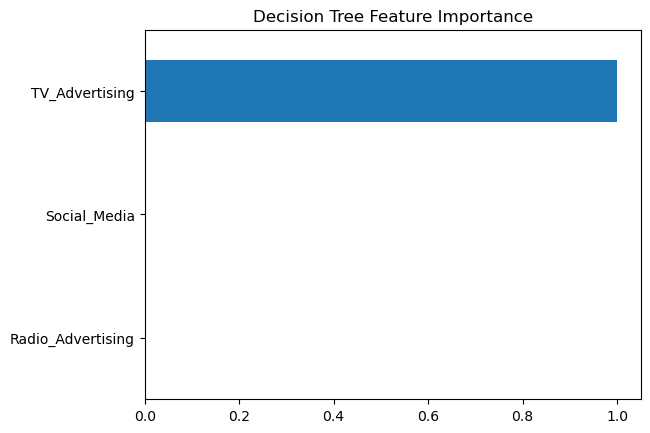

In [11]:
importances_dt.sort_values().plot(kind='barh')
plt.title("Decision Tree Feature Importance")
plt.show()

In [12]:
rf_model = RandomForestClassifier(
n_estimators=100,
max_depth=3,
random_state=42
)
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [13]:
y_pred_rf = rf_model.predict(X_test)

In [14]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

[[2 1]
 [0 0]]


In [15]:
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.6666666666666666


In [16]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      0.67      0.80         3
           1       0.00      0.00      0.00         0

    accuracy                           0.67         3
   macro avg       0.50      0.33      0.40         3
weighted avg       1.00      0.67      0.80         3



/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()}

In [17]:
importances_rf = pd.Series(rf_model.feature_importances_, index=X.columns)
print(importances_rf)

TV_Advertising       0.508623
Radio_Advertising    0.359120
Social_Media         0.132256
dtype: float64


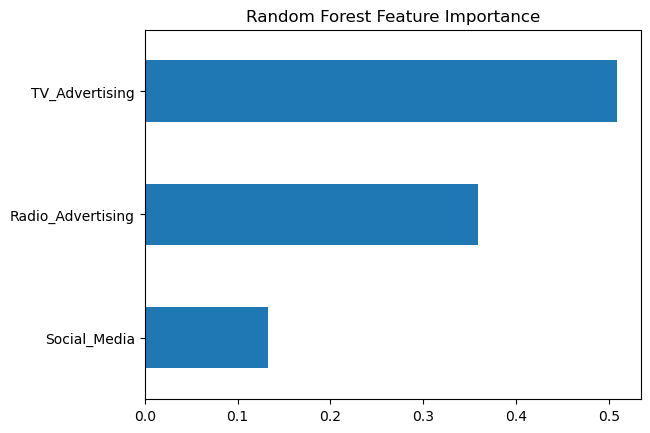

In [18]:
importances_rf.sort_values().plot(kind='barh')
plt.title("Random Forest Feature Importance")
plt.show()